# Cats vs Dogs CNN – Colab Notebook
Bu notebook, **blok blok** kodlar ve ayrıntılı Türkçe açıklamalar içerir. Tüm hücreleri sırayla çalıştırarak kedi‑köpek sınıflandırma modelinizi eğitebilirsiniz.

## 🟦 Blok 0 – Gerekli Kütüphaneler
Bu hücre TensorFlow (Keras) ve temel dosya kütüphanelerini içe aktarır.

In [ ]:
import tensorflow as tf                      # Derin‑öğrenme çatısı (Keras dâhil)
from tensorflow.keras import layers, models  # Katman ve model kısayolları
import zipfile, os, glob                     # Sıkıştırma & dosya işlemleri

## 🟦 Blok 1 – Veri Kümesini İndir & Aç
Resimleri içeren sıkıştırılmış dosyayı indirip `cats_and_dogs_filtered/` klasörüne çıkarır.

In [ ]:
!wget -q https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip

with zipfile.ZipFile("cats_and_dogs_filtered.zip") as z:
    z.extractall()                                       # → cats_and_dogs_filtered/

base_dir  = "cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")              # train/cats & train/dogs
val_dir   = os.path.join(base_dir, "validation")         # validation/cats & validation/dogs

print("Eğitim klasörü:", train_dir)
print("Doğrulama klasörü:", val_dir)

Eğitim klasörü: cats_and_dogs_filtered/train
Doğrulama klasörü: cats_and_dogs_filtered/validation


## 🟦 Blok 2 – Veriyi Dataset'e Dönüştür
Klasör yapısını Keras'ın `image_dataset_from_directory` fonksiyonuna vererek otomatik etiketli bir tf.data dataseti oluştururuz.

In [ ]:
img_size = (160, 160)   # MobileNetV2 için uygun giriş boyutu
batch_sz = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=img_size, batch_size=batch_sz,
    shuffle=True, label_mode="binary")

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=img_size, batch_size=batch_sz,
    shuffle=False, label_mode="binary")

print("Sınıflar:", train_ds.class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Sınıflar: ['cats', 'dogs']


## 🟦 Blok 3 – Data Augmentation
Modelin farklı varyasyonları görüp genelleme yapabilmesi için rastgele çevirme, döndürme ve yakınlaştırma ekliyoruz.

In [ ]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),  # yatay çevir
    layers.RandomRotation(0.1),        # ±10°
    layers.RandomZoom(0.1)             # %10 zoom
])

## 🟦 Blok 4 – Ön Eğitimli Taban (MobileNetV2)
ImageNet üzerinde eğitilmiş evrişim filtrelerini kullanıp yalnızca son katmanları kendimiz ekleyeceğiz.

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=img_size + (3,),
    include_top=False,
    weights="imagenet")
base_model.trainable = False  # ilk turda dondur

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## 🟦 Blok 5 – Tam Modelin Kurulması
Veri artırma → önişleme → özellik çıkarımı → global pool → dense → sigmoid sırasıyla modellenir.

In [ ]:
inputs = layers.Input(shape=img_size + (3,))
x = data_aug(inputs)                                           # ① Veri artır
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)     # ② Ölçekle
x = base_model(x, training=False)                              # ③ Sabit filtreler
x = layers.GlobalAveragePooling2D()(x)                         # ④ Özetle
x = layers.Dense(128, activation="relu")(x)                    # ⑤ Dense
outputs = layers.Dense(1, activation="sigmoid")(x)             # ⑥ Çıkış
model = models.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 🟦 Blok 6 – Modeli Derle
Optimizer, kayıp fonksiyonu ve takip metriklerini tanımlıyoruz.

In [ ]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

## 🟦 Blok 7 – İlk Eğitim Turu
Sadece yeni eklediğimiz dense katmanlar eğitilir.

In [ ]:
history = model.fit(train_ds, epochs=3, validation_data=val_ds)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 79ms/step - accuracy: 0.8890 - loss: 0.2244 - val_accuracy: 0.9730 - val_loss: 0.0759
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.9494 - loss: 0.1473 - val_accuracy: 0.9860 - val_loss: 0.0444
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9710 - loss: 0.0728 - val_accuracy: 0.9850 - val_loss: 0.0403


## 🟦 Blok 8 – İnce Ayar (Fine‑Tuning)
Önceki katmanları açıp çok düşük öğrenme hızıyla birkaç epoch daha eğitiriz.

In [ ]:
base_model.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy",
              metrics=["accuracy"])
history_ft = model.fit(train_ds, epochs=2, validation_data=val_ds)

Epoch 1/2
63/63 ━━━━━━━━━━━━━━━━━━━━ 42s 195ms/step - accuracy: 0.8597 - loss: 0.3370 - val_accuracy: 0.9830 - val_loss: 0.0469
Epoch 2/2
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 184ms/step - accuracy: 0.9329 - loss: 0.1596 - val_accuracy: 0.9810 - val_loss: 0.0485


## 🟦 Blok 9 – Tek Resim Tahmini
Val setinden bir resmi modele verip kedi mi köpek mi tahmin ettiğini gözlüyoruz.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
OLASILIK (1=dog): 0.4074424 → CAT


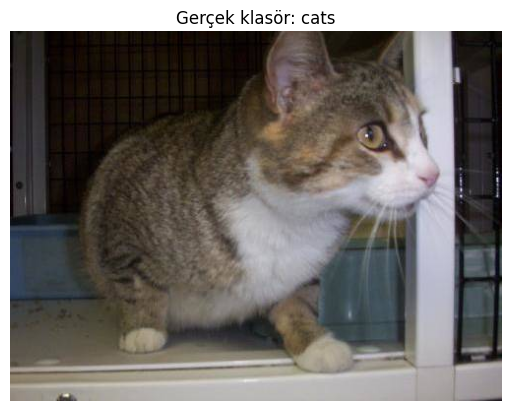

In [ ]:
import numpy as np, PIL.Image as Image, random, matplotlib.pyplot as plt
test_path = random.choice(list(glob.glob(os.path.join(val_dir, "*", "*.jpg"))))
plt.imshow(Image.open(test_path)); plt.axis('off'); plt.title("Gerçek klasör: " + os.path.basename(os.path.dirname(test_path)))
img = Image.open(test_path).resize(img_size)
arr = np.expand_dims(np.array(img) / 255.0, 0)
pred = model.predict(arr)[0][0]
print("OLASILIK (1=dog):", pred, "→", ("DOG" if pred > 0.5 else "CAT"))

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

img_size = (160, 160)
batch_sz = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    'cats_and_dogs_filtered/train',
    image_size=img_size,
    batch_size=batch_sz,
    label_mode='binary')

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    'cats_and_dogs_filtered/validation',
    image_size=img_size,
    batch_size=batch_sz,
    label_mode='binary')

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size[0], img_size[1], 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# Loss ve accuracy grafiği
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Eğitim Doğruluğu')
plt.plot(val_acc, label='Doğrulama Doğruluğu')
plt.legend()
plt.title('Doğruluk')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Eğitim Kaybı')
plt.plot(val_loss, label='Doğrulama Kaybı')
plt.legend()
plt.title('Kayıp')
plt.show()

model.save('cats_dogs_cnn_fixed.h5')
